In [17]:
from langchain_huggingface import HuggingFaceEndpoint,ChatHuggingFace
import os
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import PydanticOutputParser
from langgraph.graph import START,END,StateGraph
from typing import TypedDict,Literal,Annotated
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator
load_dotenv()

True

In [13]:
hf_token=os.getenv("HUGGINGFACEHUB_ACCESS_TOKEN")

llm1 = HuggingFaceEndpoint(
    repo_id="meta-llama/Llama-3.1-8B-Instruct",
    task="text-generation",
    huggingfacehub_api_token=hf_token,
)

generator_llm = ChatHuggingFace(llm=llm1)

llm2 = HuggingFaceEndpoint(
    repo_id="Qwen/Qwen2.5-7B-Instruct",
    task="text-generation",
    huggingfacehub_api_token=hf_token,
)

evalutor_llm = ChatHuggingFace(llm=llm2)

llm3 = HuggingFaceEndpoint(
    repo_id="meta-llama/Llama-3.1-8B-Instruct",
    task="text-generation",
    huggingfacehub_api_token=hf_token,
)

optimizer_llm = ChatHuggingFace(llm=llm3)



In [3]:
class Scores(BaseModel):
    clarity: int = Field(ge=1, le=5)
    engagement: int = Field(ge=1, le=5)
    relevance: int = Field(ge=1, le=5)

class EvaluatorSchema(BaseModel):
    evaluation:Literal["approved","need_improvment"]
    score: Scores
    feedback: str = Field(description="Actionable feedback to improve the post")



parser=PydanticOutputParser(pydantic_object=EvaluatorSchema)

In [4]:

EVALUATOR_PROMPT = PromptTemplate(template="""
You are a professional content evaluator.


Return JSON in this exact format:
 \n{format_instruction}

Topic:
{topic}

Post:
{post}
""",
input_variables=["topic","post"],
partial_variables={"format_instruction":parser.get_format_instructions()})

In [18]:
class PostGeneratorState(TypedDict):
    topic:str
    post:str
    evaluation:Literal["approved","need_improvment"]
    score:dict
    feedback:str
    iteration:int
    max_iteration:int

    post_history:Annotated[list[str],operator.add]
    feedback_history:Annotated[list[str],operator.add]
    

In [19]:
def post_generator(state:PostGeneratorState):
    post = generator_llm.invoke(
        f"Write a high-quality LinkedIn post on: {state['topic']}"
    ).content
    return {
        "post": post,
        "iteration": state["iteration"] + 1,
        "post_history":[post]
    }

In [20]:
def post_evaluator(state:PostGeneratorState):
    chain=EVALUATOR_PROMPT|evalutor_llm|parser
    response=chain.invoke({"topic":state["topic"],"post":state["post"]})
    return{"feedback":response.feedback,"score":response.score.model_dump(),"evaluation":response.evaluation,"feedback_history":[response.feedback]}
    

In [21]:
def optimizer(state:PostGeneratorState):
    improved_post = optimizer_llm.invoke(
        f"""
        Improve the post using this feedback:
        {state['feedback']}

        Keep it concise and engaging.

        Original post:
        {state['post']}
        """
    ).content
    return {"post": improved_post,"post_history":[improved_post]}

In [9]:
def check_post(state:PostGeneratorState):
    if state["evaluation"] == "approved":
        return "approved"
    if state["iteration"] >= state["max_iteration"]:
        return "approved"
    else:
        return "need_improvment"

In [10]:
graph=StateGraph(PostGeneratorState)

graph.add_node("post_generator",post_generator)
graph.add_node("post_evaluator",post_evaluator)
graph.add_node("optimizer",optimizer)

graph.add_edge(START,"post_generator")
graph.add_edge("post_generator","post_evaluator")
graph.add_conditional_edges("post_evaluator",check_post,{"approved":END,"need_improvment":"optimizer"})
graph.add_edge("optimizer","post_evaluator")

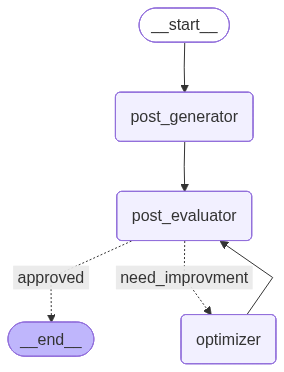

In [11]:
workflow=graph.compile()
workflow

In [22]:
intial_state={"topic":"cnn in ml",
              "iteration":0,
              "max_iteration":5}
workflow.invoke(intial_state)

{'topic': 'cnn in ml',
 'post': "**Breaking Down Barriers: The Power of CNNs in Machine Learning**\n\nAs we continue to push the boundaries of innovation in the field of machine learning, one essential technique has emerged as a game-changer: Convolutional Neural Networks (CNNs).\n\nCNNs have revolutionized the way we approach image and signal processing, enabling us to achieve state-of-the-art results in applications ranging from computer vision to natural language processing.\n\nSo, what makes CNNs so powerful?\n\n1. **Spatial Hierarchy**: CNNs are designed to take advantage of the spatial hierarchy in images, allowing them to capture local patterns and relationships between pixels.\n2. **Feature Extraction**: CNNs can automatically learn and extract relevant features from data, eliminating the need for laborious manual feature engineering.\n3. **Parallel Computing**: CNNs can be efficiently parallelized, making them well-suited for modern GPU architectures.\n\nIn practice, CNNs have